# Lab 2 · Part II: Convolutional Neural Networks and Image Classification

We train a small convolutional network (CNN) on **CIFAR-10** (60,000 colour images, 10 classes) with
cross-entropy loss and SGD with momentum, and study how learning rate, batch size and a learning-rate schedule
affect training.

The whole dataset fits in memory (~600 MB as float32), so it is loaded once as tensors on the accelerator (CUDA,
Apple MPS or CPU) and batched by indexing, with no `DataLoader`. Seeds are fixed; GPU kernels are not guaranteed
to be bit-exact, so the last digit of the numbers may differ between runs.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets
from sklearn.metrics import confusion_matrix

SEED = 0
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False
pd.options.display.float_format = "{:.4g}".format
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("device:", device)

device: cuda


## 1. Loading, splitting and normalizing CIFAR-10

`torchvision` provides the 50,000 training and 10,000 test images. We hold out 5,000 of the training images
(fixed seed) as a **validation** set, used to monitor overfitting and to compare hyperparameters, so the
**test** set is only used for the reported accuracy. Each colour channel is normalized to zero mean and unit
variance using statistics of the 45,000 training images only (no information from validation or test leaks in).

In [2]:
raw_tr = datasets.CIFAR10("data", train=True, download=True)
raw_te = datasets.CIFAR10("data", train=False, download=True)
CLASSES = raw_tr.classes

to_chw = lambda a: torch.from_numpy(a).permute(0, 3, 1, 2).float().div(255)   # uint8 NHWC -> float NCHW in [0, 1]
X_all, y_all = to_chw(raw_tr.data), torch.tensor(raw_tr.targets)
X_test, y_test = to_chw(raw_te.data), torch.tensor(raw_te.targets)

perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(SEED))
tr_idx, va_idx = perm[:45_000], perm[45_000:]
X_train, y_train = X_all[tr_idx], y_all[tr_idx]
X_val, y_val = X_all[va_idx], y_all[va_idx]

mean = X_train.mean(dim=(0, 2, 3), keepdim=True)
std = X_train.std(dim=(0, 2, 3), keepdim=True)
print("per-channel mean (R, G, B):", mean.flatten().numpy().round(4))
print("per-channel std  (R, G, B):", std.flatten().numpy().round(4))

X_raw_test = X_test                                    # un-normalized copy, for display only
norm = lambda X: ((X - mean) / std).to(device)
X_train, X_val, X_test = norm(X_train), norm(X_val), norm(X_test)
y_train, y_val, y_test = y_train.to(device), y_val.to(device), y_test.to(device)
print(f"train {tuple(X_train.shape)}, val {tuple(X_val.shape)}, test {tuple(X_test.shape)}")
print("after normalization (train): mean", X_train.mean(dim=(0, 2, 3)).cpu().numpy().round(3),
      "std", X_train.std(dim=(0, 2, 3)).cpu().numpy().round(3))

per-channel mean (R, G, B): [0.4912 0.482  0.4464]
per-channel std  (R, G, B): [0.2472 0.2436 0.2617]


train (45000, 3, 32, 32), val (5000, 3, 32, 32), test (10000, 3, 32, 32)
after normalization (train): mean [0. 0. 0.] std [1. 1. 1.]


## 2. Looking at the data

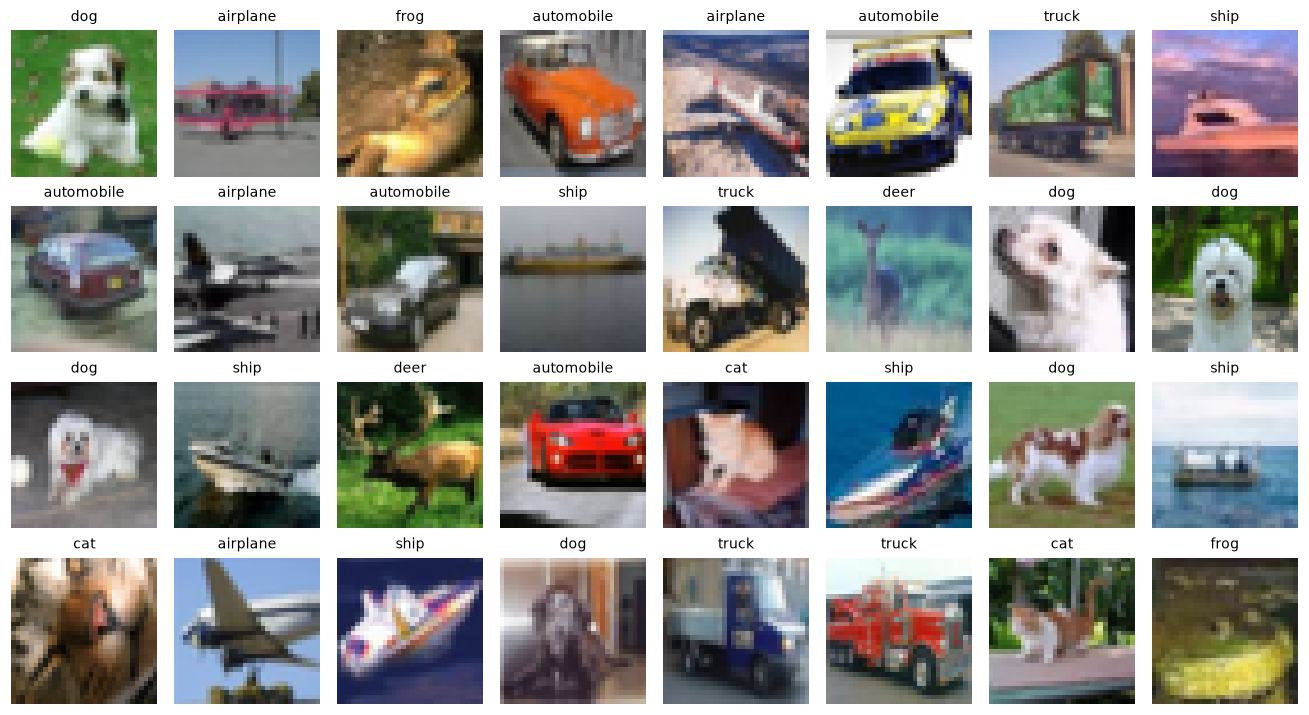

image dimensions: 3 x 32 x 32 (channels x height x width)
number of classes: 10: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
input dimension: 3 * 32 * 32 = 3072
class counts in train: [4518, 4492, 4506, 4496, 4468, 4493, 4498, 4494, 4502, 4533]


In [3]:
g = torch.Generator().manual_seed(1)
idx = torch.randperm(len(X_raw_test), generator=g)[:32]
fig, axes = plt.subplots(4, 8, figsize=(12, 6.6))
for ax, i in zip(axes.flat, idx):
    ax.imshow(X_raw_test[i].permute(1, 2, 0).numpy())
    ax.set_title(CLASSES[y_test[i]], fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

C, H, W = X_train.shape[1:]
print(f"image dimensions: {C} x {H} x {W} (channels x height x width)")
print(f"number of classes: {len(CLASSES)}:", CLASSES)
print(f"input dimension: {C} * {H} * {W} = {C * H * W}")
print("class counts in train:", torch.bincount(y_train).tolist())

**Observations.** Images are 3×32×32 (RGB, 32×32 pixels), there are 10 classes (airplane, automobile, bird, cat, deer,
dog, frog, horse, ship, truck), so the input space has $3\cdot32\cdot32 = 3072$ dimensions. The classes are balanced
(4,468–4,533 training images each), so plain accuracy is a fair metric. The images are tiny, and some classes are
hard to tell apart even for a human at this resolution (cat/dog, deer/horse). After normalization the training
channels have mean 0 and standard deviation 1 by construction; validation and test are only approximately standardized.

## 3. CNN architecture

```
input 3×32×32 → Conv(3→32, 3×3, pad 1) → ReLU → MaxPool 2×2 → Conv(32→64, 3×3, pad 1) → ReLU → MaxPool 2×2
              → Flatten (64·8·8 = 4096) → FC(4096→128) → ReLU → FC(128→10) → softmax
```

Padding 1 keeps the spatial size through each convolution, so only the pooling layers halve it (32 → 16 → 8).

**Softmax and the loss.** `nn.CrossEntropyLoss` already contains a (numerically stable) log-softmax followed by the
negative log-likelihood, so it expects raw **logits**. Applying an explicit softmax in `forward()` before it would
squash the gradients (softmax would be applied twice). Hence `forward()` returns logits for training, and the
softmax output layer is applied at inference in `predict_proba()`. The model is the specified network with a
softmax output layer; the softmax just lives inside the loss during training.

In [4]:
class CNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc = nn.Linear(64 * 8 * 8, 128)
        self.out = nn.Linear(128, n_classes)

    def forward(self, x):                      # returns logits
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = F.relu(self.fc(x.flatten(1)))
        return self.out(x)

    @torch.no_grad()
    def predict_proba(self, x):                # softmax output layer, used at inference
        return F.softmax(self(x), dim=1)

def param_table(model):
    rows = [{"layer": name, "weights": m.weight.numel(), "biases": m.bias.numel(),
             "total": m.weight.numel() + m.bias.numel()}
            for name, m in model.named_children() if hasattr(m, "weight")]
    t = pd.DataFrame(rows).set_index("layer")
    t.loc["total"] = t.sum()
    return t.astype(int)

torch.manual_seed(SEED)
model = CNN().to(device)
print(model)
assert param_table(model).loc["total", "total"] == sum(p.numel() for p in model.parameters())
param_table(model)

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc): Linear(in_features=4096, out_features=128, bias=True)
  (out): Linear(in_features=128, out_features=10, bias=True)
)


,weights,biases,total
layer,,,
conv1,864,32,896
conv2,18432,64,18496
fc,524288,128,524416
out,1280,10,1290
total,544864,234,545098


**Observations.** The network has **545,098 parameters**, of which 96% (524,416) sit in the fully connected
layer: flattening $64\times8\times8 = 4096$ features into 128 units costs $4096\cdot128$ weights. The two convolutions
together have only 19,392 parameters (3.6%) because their filters are shared across all positions, although they
account for most of the computation. A large dense layer on top of a few conv features is a typical recipe for
overfitting, which we see below.

## 4. Loss and optimizer

Loss: `nn.CrossEntropyLoss` (mean over the batch). Optimizer: `torch.optim.SGD` with **learning rate 0.01** and
**momentum 0.9**. Momentum accumulates a running average of gradients, which smooths the mini-batch noise and
speeds up progress along consistent directions; with it the effective step is about $\eta/(1-0.9) = 10\eta$,
so a nominal 0.01 acts like 0.1 for plain SGD. This is a standard, fairly safe choice for a small CNN without
batch norm: 0.1 is typically too aggressive for this setup and 0.001 too slow for a ~15-epoch budget. We
verify this in the experiments of step 6.

## 5. Training

`run()` trains for a number of epochs with mini-batches reshuffled every epoch, and records after every epoch the
loss and accuracy on the train, validation and test sets (evaluated in `eval` mode on the full sets, so the
train numbers are not the noisy running averages of the epoch). Batch size 64, **15 epochs**.

In [5]:
loss_fn = nn.CrossEntropyLoss()

@torch.no_grad()
def evaluate(model, X, y, bs=5000):
    model.eval()
    loss, correct = 0.0, 0
    for i in range(0, len(X), bs):
        logits = model(X[i:i + bs])
        loss += F.cross_entropy(logits, y[i:i + bs], reduction="sum").item()
        correct += (logits.argmax(1) == y[i:i + bs]).sum().item()
    return loss / len(X), correct / len(X)

def run(epochs=15, lr=0.01, momentum=0.9, batch_size=64, schedule=None, seed=SEED,
        eval_sets=("train", "val", "test"), verbose=False):
    torch.manual_seed(seed)
    model = CNN().to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    steps = -(-len(X_train) // batch_size)
    sched = {None: None,
             "cosine": lambda: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * steps),
             "step": lambda: torch.optim.lr_scheduler.StepLR(opt, step_size=max(epochs // 3, 1) * steps, gamma=0.1),
             }[schedule]
    sched = sched() if sched else None
    sets = {"train": (X_train, y_train), "val": (X_val, y_val), "test": (X_test, y_test)}
    g = torch.Generator().manual_seed(seed)
    hist, t0 = [], time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        order = torch.randperm(len(X_train), generator=g).to(device)
        for i in range(0, len(order), batch_size):
            idx = order[i:i + batch_size]
            loss = loss_fn(model(X_train[idx]), y_train[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
            if sched: sched.step()
        row = {"epoch": epoch, "time": time.time() - t0}
        for name in eval_sets:
            row[f"{name}_loss"], row[f"{name}_acc"] = evaluate(model, *sets[name])
        hist.append(row)
        if verbose:
            print(f"epoch {epoch:2d} | " + " | ".join(f"{n} loss {row[n + '_loss']:.3f} acc {row[n + '_acc']:.4f}" for n in eval_sets))
    return model, pd.DataFrame(hist).set_index("epoch")

t0 = time.time()
model, hist = run(epochs=15, verbose=True)
print(f"\ntraining time: {time.time() - t0:.0f} s")

epoch  1 | train loss 1.080 acc 0.6195 | val loss 1.171 acc 0.5874 | test loss 1.134 acc 0.6055


epoch  2 | train loss 0.824 acc 0.7116 | val loss 0.959 acc 0.6630 | test loss 0.948 acc 0.6658


epoch  3 | train loss 0.719 acc 0.7524 | val loss 0.941 acc 0.6800 | test loss 0.921 acc 0.6856


epoch  4 | train loss 0.549 acc 0.8088 | val loss 0.902 acc 0.6942 | test loss 0.876 acc 0.7069


epoch  5 | train loss 0.448 acc 0.8465 | val loss 0.913 acc 0.6928 | test loss 0.900 acc 0.7053


epoch  6 | train loss 0.315 acc 0.8920 | val loss 0.958 acc 0.7094 | test loss 0.946 acc 0.7099


... (5 outputs left out)

epoch 12 | train loss 0.081 acc 0.9716 | val loss 1.773 acc 0.6922 | test loss 1.698 acc 0.7078


epoch 13 | train loss 0.106 acc 0.9642 | val loss 1.703 acc 0.6870 | test loss 1.682 acc 0.6954


epoch 14 | train loss 0.068 acc 0.9757 | val loss 1.859 acc 0.7010 | test loss 1.821 acc 0.7093


epoch 15 | train loss 0.056 acc 0.9807 | val loss 1.971 acc 0.6994 | test loss 1.934 acc 0.7107

training time: 21 s


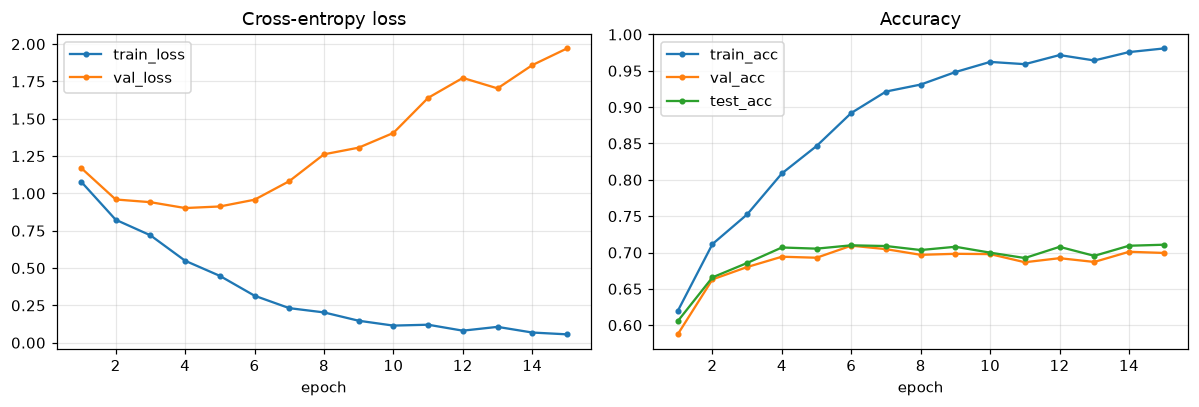

lowest val loss at epoch 4 (0.902); final: train acc 0.9807, val acc 0.6994, test acc 0.7107


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
hist[["train_loss", "val_loss"]].plot(ax=ax[0], marker="o", ms=3, title="Cross-entropy loss")
hist[["train_acc", "val_acc", "test_acc"]].plot(ax=ax[1], marker="o", ms=3, title="Accuracy")
for a in ax: a.set_xlabel("epoch")
plt.tight_layout(); plt.show()

best = hist.val_loss.idxmin()
print(f"lowest val loss at epoch {best} ({hist.val_loss[best]:.3f}); "
      f"final: train acc {hist.train_acc.iloc[-1]:.4f}, val acc {hist.val_acc.iloc[-1]:.4f}, test acc {hist.test_acc.iloc[-1]:.4f}")

probabilities sum to 1: True | test accuracy 0.7107


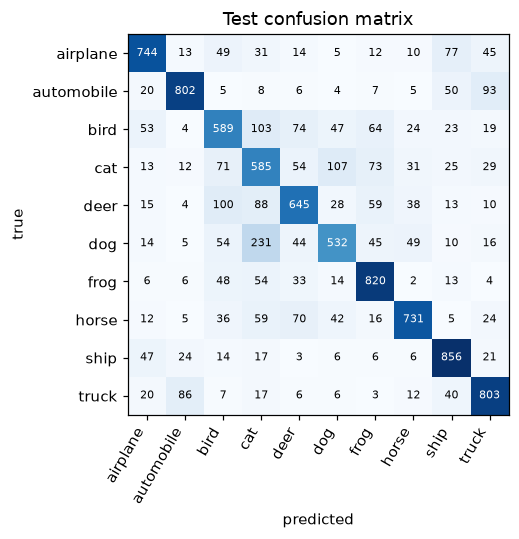

dog          0.532
cat          0.585
bird         0.589
deer         0.645
horse        0.731
airplane     0.744
automobile   0.802
truck        0.803
frog          0.82
ship         0.856

most frequent confusion: true dog -> predicted cat (231 images)


In [7]:
with torch.no_grad():
    model.eval()
    proba = torch.cat([model.predict_proba(X_test[i:i + 5000]) for i in range(0, len(X_test), 5000)])
pred = proba.argmax(1).cpu().numpy()
true = y_test.cpu().numpy()
print("probabilities sum to 1:", torch.allclose(proba.sum(1), torch.ones(len(proba), device=device), atol=1e-4),
      f"| test accuracy {np.mean(pred == true):.4f}")

cm = confusion_matrix(true, pred)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set(xticks=range(10), yticks=range(10), xlabel="predicted", ylabel="true", title="Test confusion matrix")
ax.set_xticklabels(CLASSES, rotation=60, ha="right"); ax.set_yticklabels(CLASSES); ax.grid(False)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.show()
per_class = pd.Series(cm.diagonal() / cm.sum(1), index=CLASSES, name="test accuracy").sort_values()
print(per_class.round(3).to_string())
off = cm - np.diag(cm.diagonal())
i, j = np.unravel_index(off.argmax(), off.shape)
print(f"\nmost frequent confusion: true {CLASSES[i]} -> predicted {CLASSES[j]} ({off[i, j]} images)")

**Observations.**
- **Overfitting after ~4 epochs.** The training loss falls steadily to 0.06 (98% train accuracy), but the validation
  loss is lowest at epoch 4 (0.90) and then rises to 1.97 at epoch 15. The model first learns general features and then
  memorizes the 45k training images (545k parameters, no regularization or augmentation).
- **Accuracy hides it.** Validation and test accuracy plateau at ≈ 70-71% from epoch 4 on, while the loss doubles.
  The loss grows because the network becomes overconfident on its mistakes (cross-entropy punishes a confident wrong
  prediction heavily), while the argmax decisions barely change. Early stopping around epoch 4-6 would give the best
  loss at about the same accuracy.
- **Final test accuracy: 71.1%** (train 98.1%, val 69.9%), against 10% for chance. Validation and test curves agree
  within about a point, so the validation set is a reliable stand-in for the test set. Accuracy fluctuates by ±1% between epochs
  at a constant learning rate, so the differences between the last epochs are noise.
- **Per class:** ship (86%), frog (82%), truck and automobile (80%) are the easiest: distinctive shapes or backgrounds.
  Dog (53%), cat (59%) and bird (59%) are the hardest, and the most frequent confusion is dog → cat (231 test
  images). The animal classes are confused with each other, whereas vehicles are mostly confused with other vehicles.

## 6. Learning rate, batch size and schedule

Compact grid, each run 8 epochs from the same initialization seed, momentum 0.9, compared on the **validation**
set (the test set stays untouched): learning rate ∈ {0.001, 0.01, 0.1} at batch size 64; batch size ∈ {32, 64, 256}
at learning rate 0.01; and a cosine learning-rate schedule (lr decays from 0.01 to 0 over the run, per step).
Note that for a fixed number of epochs, a smaller batch means more optimizer steps (704 / 1407 per epoch for
batch 64 / 32, vs 176 for batch 256).

In [8]:
EP = 8
configs = {
    "lr=0.001, bs=64": dict(lr=0.001, batch_size=64),
    "lr=0.01, bs=64":  dict(lr=0.01, batch_size=64),
    "lr=0.1, bs=64":   dict(lr=0.1, batch_size=64),
    "lr=0.01, bs=32":  dict(lr=0.01, batch_size=32),
    "lr=0.01, bs=256": dict(lr=0.01, batch_size=256),
    "lr=0.01, bs=64, cosine": dict(lr=0.01, batch_size=64, schedule="cosine"),
}
results = {}
for name, cfg in configs.items():
    _, h = run(epochs=EP, eval_sets=("train", "val"), **cfg)
    results[name] = h
    print(f"{name:24s} val acc {h.val_acc.iloc[-1]:.4f}  ({h.time.iloc[-1]:.0f} s)")

lr=0.001, bs=64          val acc 0.6462  (11 s)


lr=0.01, bs=64           val acc 0.6968  (10 s)


lr=0.1, bs=64            val acc 0.4788  (10 s)


lr=0.01, bs=32           val acc 0.6944  (20 s)


lr=0.01, bs=256          val acc 0.6968  (3 s)


lr=0.01, bs=64, cosine   val acc 0.7384  (11 s)


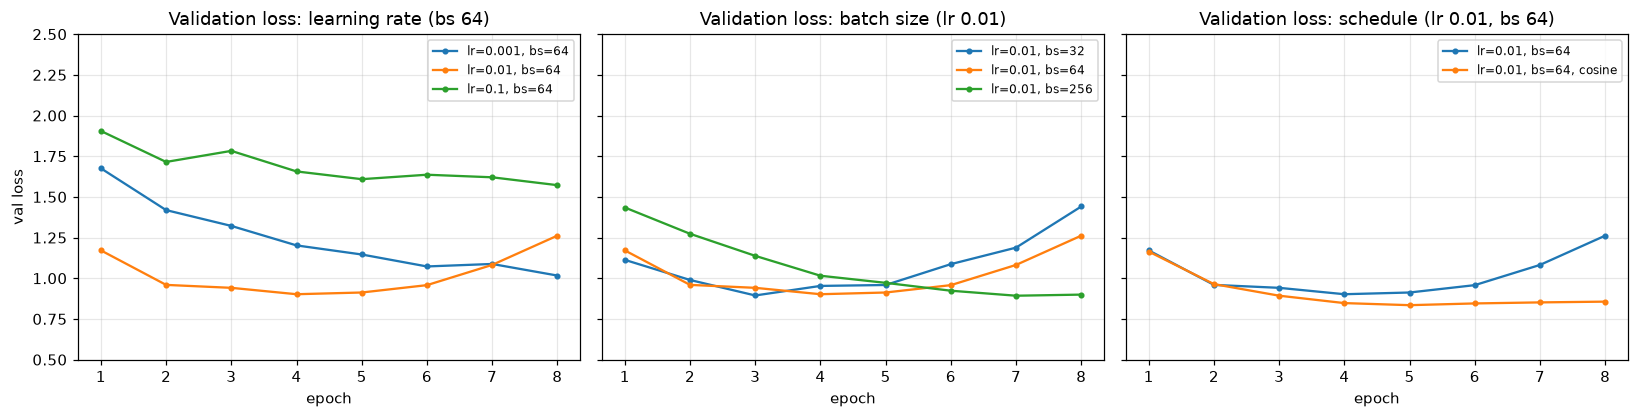

,final train loss,final val loss,min val loss,epoch of min,final train acc,final val acc,best val acc,time (s)
"lr=0.001, bs=64",0.8998,1.017,1.017,8,0.6889,0.6462,0.6462,10.64
"lr=0.01, bs=64",0.203,1.262,0.902,4,0.9311,0.6968,0.7094,10.4
"lr=0.1, bs=64",1.396,1.572,1.572,8,0.5237,0.4788,0.4788,9.877
"lr=0.01, bs=32",0.1869,1.441,0.8943,3,0.9374,0.6944,0.705,20.34
"lr=0.01, bs=256",0.6103,0.8996,0.8928,7,0.7895,0.6968,0.6968,3.493
"lr=0.01, bs=64, cosine",0.2392,0.8564,0.8347,5,0.9325,0.7384,0.7384,10.53


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.9), sharey=True)
groups = [("learning rate (bs 64)", ["lr=0.001, bs=64", "lr=0.01, bs=64", "lr=0.1, bs=64"]),
          ("batch size (lr 0.01)", ["lr=0.01, bs=32", "lr=0.01, bs=64", "lr=0.01, bs=256"]),
          ("schedule (lr 0.01, bs 64)", ["lr=0.01, bs=64", "lr=0.01, bs=64, cosine"])]
for a, (title, names) in zip(ax, groups):
    for n in names:
        a.plot(results[n].index, results[n].val_loss, marker="o", ms=3, label=n)
    a.set(title=f"Validation loss: {title}", xlabel="epoch"); a.legend(fontsize=8)
ax[0].set_ylabel("val loss"); ax[0].set_ylim(0.5, 2.5)
plt.tight_layout(); plt.show()

summary = pd.DataFrame({n: {"final train loss": h.train_loss.iloc[-1], "final val loss": h.val_loss.iloc[-1],
                            "min val loss": h.val_loss.min(), "epoch of min": h.val_loss.idxmin(),
                            "final train acc": h.train_acc.iloc[-1], "final val acc": h.val_acc.iloc[-1],
                            "best val acc": h.val_acc.max(), "time (s)": h.time.iloc[-1]}
                        for n, h in results.items()}).T
summary

**Observations** (8 epochs each, single seed, validation set of 5,000 images: one standard error of the accuracy is ≈ 0.65 points, so
differences of 1 point or less are noise).
- **Learning rate.** 0.001 is too low: the loss decreases slowly and is still decreasing at epoch 8 (val loss 1.02, train accuracy only
  69%): underfitting within this budget. 0.01 learns quickly (val loss 0.90 at epoch 4), but overfits afterwards (1.26 at epoch 8).
  0.1 with momentum 0.9 is too high: the loss stays above 1.5, train accuracy reaches only 52%, and the training is erratic. It sits at
  the edge of divergence: in a trial run with non-deterministic kernels it blew up to NaN. The usual pattern: too low is slow, too high is unstable, with the best
  value around 0.01 here.
- **Batch size** (lr 0.01). The best validation loss is almost the same (0.89-0.90) for 32, 64 and 256, but it is reached at different
  times: epoch 3, 4 and 7. With a fixed epoch count, a smaller batch means more updates per epoch (1407 / 704 / 176) with noisier gradients
  (the gradient noise scales as $1/\sqrt{B}$). So batch 32 fits and overfits fastest (final val loss 1.44), and batch 256 is still at its
  minimum after 8 epochs (train accuracy 79%). Batch 256 is also ~7× faster per epoch on the GPU (3 s vs 21 s), since the
  GPU processes a large batch almost for free, so for wall-clock time a large batch with a larger learning rate is attractive.
  Final validation accuracies are the same within noise (69.4-69.7%).
- **Schedule.** Cosine decay of the learning rate from 0.01 to 0 gives the best result of the whole study: val loss 0.84 at epoch 5, 0.86 at the
  end instead of 1.26 for constant lr, and **73.8% val accuracy vs 69.7%**. The large rate early on makes fast progress; the small rate
  at the end lets the weights settle instead of jumping around the minimum, and the loss no longer rises. The train accuracy is the same (93%), so the gain
  comes from a better solution, not from less fitting. (We did not re-run the 15-epoch training with it, to keep the test set out of the tuning.)
- Overfitting begins within 3-7 epochs in every setting that learns fast; lr 0.001 and batch 256 simply have not reached it yet.

## Summary
- A small CNN (2 conv + 2 max-pool + 1 hidden FC layer, 545k parameters, 96% of them in the FC layer) trained for 15 epochs with SGD
  (lr 0.01, momentum 0.9, batch 64) reaches **71.1% test accuracy**.
- It overfits quickly: the validation loss is minimal at epoch 4 and then rises steadily (0.90 → 1.97) while the train accuracy goes to 98%
  and the validation/test accuracy stays at ≈ 70%. Accuracy alone hides this, so the loss curves are what to monitor; early stopping,
  data augmentation, dropout or weight decay would be the natural next steps.
- Learning rate matters most: 0.001 underfits in the epoch budget, 0.1 is unstable, 0.01 is a good default. Batch size mainly
  changes the number of updates per epoch and the noise: smaller batches reach (and pass) the optimum in fewer epochs, larger
  ones are much faster per epoch on a GPU but need more epochs or a larger learning rate.
- A cosine learning-rate schedule was the single most effective change (73.8% vs 69.7% validation accuracy, no late rise of the loss),
  at no cost.
- Difficult classes are the animals (dog, cat, bird); vehicles and ships are easiest. Remaining caveats: single seeds,
  short sweeps, and hyperparameters compared on the validation set only.